In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE
import itertools
from inference_utils import preprocess_and_select_25

In [2]:
PROJECT_DIR = Path(r"E:\DataMining_Group32")
NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"
if str(NOTEBOOKS_DIR) not in sys.path:
    sys.path.append(str(NOTEBOOKS_DIR))

from inference_utils import preprocess_and_select_25

RAW_SPLIT_DIR = PROJECT_DIR / "data" / "raw_split"

print("Loading raw split data...")
X_train_raw = pd.read_csv(RAW_SPLIT_DIR / "X_train_before.csv")
X_val_raw = pd.read_csv(RAW_SPLIT_DIR / "X_val_before.csv")
X_test_raw = pd.read_csv(RAW_SPLIT_DIR / "X_test_before.csv")

y_train_raw = pd.read_csv(RAW_SPLIT_DIR / "y_train.csv").squeeze("columns")
y_val = pd.read_csv(RAW_SPLIT_DIR / "y_val.csv").squeeze("columns")
y_test = pd.read_csv(RAW_SPLIT_DIR / "y_test.csv").squeeze("columns")

print("Applying preprocessing, deduplication, and selecting top 25 features...")

# 1. برای Train: هم X و هم y را می‌دهیم تا Deduplication انجام شود
X_train, y_train = preprocess_and_select_25(X_train_raw, PROJECT_DIR, y=y_train_raw)

# 2. برای Validation و Test: فقط X را می‌دهیم (بدون حذف سطر)
X_val = preprocess_and_select_25(X_val_raw, PROJECT_DIR)
X_test = preprocess_and_select_25(X_test_raw, PROJECT_DIR)

print(f"\nTrain Shape:      X={X_train.shape} | y={y_train.shape}")
print(f"Validation Shape: X={X_val.shape} | y={y_val.shape}")
print(f"Test Shape:       X={X_test.shape} | y={y_test.shape}")

Loading raw split data...
Applying preprocessing, deduplication, and selecting top 25 features...
[Deduplication] X_train before: 70,040 rows
[Deduplication] X_train after:  70,024 rows
[Deduplication] Removed: 16 duplicate rows

Train Shape:      X=(70024, 25) | y=(70024,)
Validation Shape: X=(14960, 25) | y=(14960,)
Test Shape:       X=(15000, 25) | y=(15000,)


In [3]:
y_train_xgb = y_train - 1

smote_strategies = {
    "no_smote": None,
    "smote_1_4_to_5000": {0: 5000, 3: 5000},
    "smote_1_4_to_10000": {0: 10000, 3: 10000},
    "smote_moderate": {0: 10000, 2: 20000, 3: 10000},
}

# محاسبه وزن نمونه ها در هر کلاس
def calculate_sample_weights(y_data):
    class_counts = pd.Series(y_data).value_counts().sort_index()
    n_samples = len(y_data)
    n_classes = len(class_counts)
    weights = {cls: n_samples / (n_classes * count) for cls, count in class_counts.items()}
    return pd.Series(y_data).map(weights).values

In [4]:
print("\n" + "="*50)
print("STARTING EXTENDED TUNING (SMOTE Strategies + XGBoost Params)")
print("="*50)

param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [6, 8, 10],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0]
}

keys, values = zip(*param_grid.items())
combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]
total_combinations = len(combinations) * len(smote_strategies)

best_f1 = 0
best_params = {}
best_model = None
best_strategy_name = None

import time
start_time = time.time()
iteration_count = 0

for strategy_name, strategy in smote_strategies.items():
    
    if strategy is None:
        X_fit = X_train.copy()
        y_fit = y_train_xgb.copy()
        print(f"\n--- Strategy: {strategy_name} (Original Data) ---")
    else:
        smote = SMOTE(sampling_strategy=strategy, random_state=42)
        X_fit, y_fit = smote.fit_resample(X_train, y_train_xgb)
        print(f"\n--- Strategy: {strategy_name} | New Train Shape: {X_fit.shape} ---")
    
    sample_weights = calculate_sample_weights(y_fit)
    
    for params in combinations:
        iteration_count += 1
        xgb = XGBClassifier(**params, random_state=42, eval_metric='mlogloss')
        xgb.fit(X_fit, y_fit, sample_weight=sample_weights)

        y_val_pred_xgb = xgb.predict(X_val)
        y_val_pred = y_val_pred_xgb + 1 

        val_f1 = f1_score(y_val, y_val_pred, average='macro')

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_params = params
            best_model = xgb
            best_strategy_name = strategy_name
            
            elapsed_mins = (time.time() - start_time) / 60
            progress_percent = (iteration_count / total_combinations) * 100
            print(f" [New Best] Time: {elapsed_mins:.1f} min | Progress: {progress_percent:.0f}% | Strat: {strategy_name} | F1={val_f1:.4f} | Params: {params}")

end_time = time.time()
total_time = (end_time - start_time) / 60

print("\n" + "="*50)
print("SMART TUNING COMPLETE - BEST CONFIGURATION")
print("="*50)
print(f"Total Time: {total_time:.1f} minutes")
print(f"Best SMOTE Strategy: {best_strategy_name}")
for p, v in best_params.items():
    print(f" {p}: {v}")
print(f" Best Validation Macro F1: {best_f1:.4f}")


STARTING EXTENDED TUNING (SMOTE Strategies + XGBoost Params)

--- Strategy: no_smote (Original Data) ---
 [New Best] Time: 0.1 min | Progress: 0% | Strat: no_smote | F1=0.4373 | Params: {'n_estimators': 100, 'learning_rate': 0.01, 'max_depth': 6, 'subsample': 0.7, 'colsample_bytree': 0.7}
 [New Best] Time: 0.9 min | Progress: 1% | Strat: no_smote | F1=0.4675 | Params: {'n_estimators': 100, 'learning_rate': 0.01, 'max_depth': 8, 'subsample': 0.7, 'colsample_bytree': 0.7}
 [New Best] Time: 1.0 min | Progress: 1% | Strat: no_smote | F1=0.4687 | Params: {'n_estimators': 100, 'learning_rate': 0.01, 'max_depth': 8, 'subsample': 0.7, 'colsample_bytree': 0.8}
 [New Best] Time: 2.0 min | Progress: 2% | Strat: no_smote | F1=0.4982 | Params: {'n_estimators': 100, 'learning_rate': 0.01, 'max_depth': 10, 'subsample': 0.7, 'colsample_bytree': 0.7}
 [New Best] Time: 2.5 min | Progress: 2% | Strat: no_smote | F1=0.4999 | Params: {'n_estimators': 100, 'learning_rate': 0.01, 'max_depth': 10, 'subsample

In [5]:
# Testing n_estimators & subsample & max_depth limits
print("\n" + "="*50)
print("FAST TESTS: Checking boundaries for the best strategy")
print("="*50)

test_configs = [
    {"name": "n_estimators = 400", "params": {"n_estimators": 400}},
    {"name": "subsample = 0.6", "params": {"subsample": 0.6}},
    {"name": "max_depth=12", "params": {"max_depth": 12}},
]

print(f"Current Best Macro F1: {best_f1:.4f} (Strategy: {best_strategy_name})")
print("-" * 50)

# ابتدا باید داده های بهترین استراتژی را دوباره بسازیم تا تست ها روی پایه درست انجام شود
if smote_strategies[best_strategy_name] is None:
    X_fit_best, y_fit_best = X_train, y_train_xgb
else:
    smote_best = SMOTE(sampling_strategy=smote_strategies[best_strategy_name], random_state=42)
    X_fit_best, y_fit_best = smote_best.fit_resample(X_train, y_train_xgb)
sample_weights_best = calculate_sample_weights(y_fit_best)


for test in test_configs:
    params_test = best_params.copy()
    params_test.update(test["params"])

    xgb_test = XGBClassifier(**params_test, random_state=42, eval_metric='mlogloss')
    xgb_test.fit(X_fit_best, y_fit_best, sample_weight=sample_weights_best)

    y_pred_test = xgb_test.predict(X_val) + 1
    f1_test = f1_score(y_val, y_pred_test, average='macro')

    diff = f1_test - best_f1
    status = "WINNER 🏆" if diff > 0 else "WORSE ❌"

    print(f"[{status}] Test: {test['name']:20s} | New F1: {f1_test:.4f} | Difference: {diff:+.4f}")

    if diff > 0:
        best_model = xgb_test
        best_f1 = f1_test
        best_params = params_test
        print(f" -> Best model updated to: {test['name']}")

print("\n" + "="*50)
print(f"FINAL Best Macro F1: {best_f1:.4f}")
print(f"FINAL Best Parameters: {best_params}")
print(f"FINAL Best Strategy: {best_strategy_name}")
print("="*50)


FAST TESTS: Checking boundaries for the best strategy
Current Best Macro F1: 0.5870 (Strategy: smote_1_4_to_5000)
--------------------------------------------------
[WORSE ❌] Test: n_estimators = 400   | New F1: 0.5772 | Difference: -0.0098
[WORSE ❌] Test: subsample = 0.6      | New F1: 0.5833 | Difference: -0.0036
[WORSE ❌] Test: max_depth=12         | New F1: 0.5753 | Difference: -0.0117

FINAL Best Macro F1: 0.5870
FINAL Best Parameters: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 10, 'subsample': 0.8, 'colsample_bytree': 0.7}
FINAL Best Strategy: smote_1_4_to_5000


In [6]:
xgb_model = best_model
y_pred_xgb_final = xgb_model.predict(X_val) + 1
acc_xgb = accuracy_score(y_val, y_pred_xgb_final)

print("\n" + "="*50)
print("XGBOOST (SMOTEd) - FINAL VALIDATION RESULTS")
print("="*50)
print(f"Accuracy: {acc_xgb:.4f}")
print(f"Macro F1-Score: {best_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_pred_xgb_final, zero_division=0))


XGBOOST (SMOTEd) - FINAL VALIDATION RESULTS
Accuracy: 0.8467
Macro F1-Score: 0.5870

Classification Report:
              precision    recall  f1-score   support

           1       0.42      0.50      0.46       127
           2       0.94      0.87      0.90     11915
           3       0.63      0.84      0.72      2513
           4       0.26      0.28      0.27       405

    accuracy                           0.85     14960
   macro avg       0.56      0.62      0.59     14960
weighted avg       0.87      0.85      0.85     14960



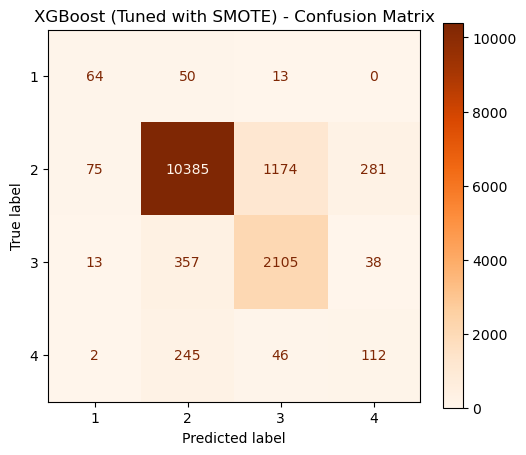

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
cm_xgb = confusion_matrix(y_val, y_pred_xgb_final, labels=[1, 2, 3, 4])
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=[1, 2, 3, 4])
disp_xgb.plot(cmap='Oranges', ax=ax, values_format='d')
ax.set_title("XGBoost (Tuned with SMOTE) - Confusion Matrix")
plt.show()

In [8]:
# Feature Importance Analysis
importance_xgb = pd.Series(xgb_model.get_booster().get_score(importance_type='gain'), index=X_train.columns).sort_values(ascending=False).head(10)
print("\nTop 10 Important Features (XGBoost - based on Gain):")
print(importance_xgb)


Top 10 Important Features (XGBoost - based on Gain):
remainder__f8_is_slow_traffic     64.982452
remainder__f1                     32.889191
num_robust__f7                    19.854589
remainder__f8_is_highway          18.069696
remainder__f8_is_severe_crash     14.301606
remainder__f9_is_highway_route    14.088150
cyclic__start_month                7.060917
remainder__f10                     6.668283
bool__f30                          6.183001
num_robust__duration_minutes       5.865057
dtype: float64


In [10]:
import joblib
model_save_path = PROJECT_DIR / "models" / "xgboost_model.pkl"
joblib.dump(xgb_model, model_save_path)
print(f"\n[SUCCESS] Ultimate XGBoost Model saved to: {model_save_path}")


[SUCCESS] Ultimate XGBoost Model saved to: E:\DataMining_Group32\models\xgboost_model.pkl
